# Lab 3 — CNN Error Analysis on CIFAR-10

This lab analyzes the **deeper CNN**, which produced Lab 2's best validation accuracy. The goals are to:

1. Inspect misclassified validation images.
2. Identify confusing classes and classes with low recall.
3. Distinguish underfitting from overfitting using training and validation curves.
4. Propose next improvements grounded in those observations.

The same 45,000/5,000 training/validation split and training settings are used for comparability. The official CIFAR-10 test set remains unused.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

seed = 42
torch.manual_seed(seed)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print('torch', torch.__version__, ' device', device)

torch 2.14.1  device mps


## 1. Data and selected model

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

full_train_ds = datasets.CIFAR10(
    './data', train=True, download=True, transform=transform
)
train_ds, val_ds = random_split(
    full_train_ds,
    [45_000, 5_000],
    generator=torch.Generator().manual_seed(seed),
)
train_loader = DataLoader(
    train_ds,
    batch_size=128,
    shuffle=True,
    generator=torch.Generator().manual_seed(seed),
)
val_loader = DataLoader(val_ds, batch_size=512, shuffle=False)
class_names = full_train_ds.classes

print('training samples  :', len(train_ds))
print('validation samples:', len(val_ds))

training samples  : 45000
validation samples: 5000


In [3]:
class DeeperCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(seed)
model = DeeperCNN().to(device)
print('parameters:', sum(p.numel() for p in model.parameters()))

parameters: 356810


## 2. Training behavior: underfitting vs. overfitting

Training accuracy is recorded alongside validation accuracy. A growing gap between them, especially together with rising validation loss, indicates overfitting. The checkpoint with the highest validation accuracy is retained for the later error analysis.

In [4]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, targets in loader:
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            total_loss += criterion(logits, targets).item() * images.size(0)
            total_correct += (logits.argmax(1) == targets).sum().item()
            total_samples += images.size(0)

    return total_loss / total_samples, total_correct / total_samples

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
epochs = 10
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
}
best_val_acc = 0.0
best_epoch = 0
best_state = None

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        total_correct += (logits.argmax(1) == targets).sum().item()
        total_samples += images.size(0)

    train_loss = total_loss / total_samples
    train_acc = total_correct / total_samples
    val_loss, val_acc = evaluate(model, val_loader, criterion)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_state = {
            name: value.detach().cpu().clone()
            for name, value in model.state_dict().items()
        }

    print(
        f'epoch {epoch + 1:2d}  train_loss {train_loss:.4f}  '
        f'train_acc {train_acc * 100:.2f}%  val_loss {val_loss:.4f}  '
        f'val_acc {val_acc * 100:.2f}%'
    )

model.load_state_dict(best_state)
print(f'\nRestored best checkpoint: epoch {best_epoch}, validation accuracy {best_val_acc * 100:.2f}%')

epoch  1  train_loss 1.6079  train_acc 40.81%  val_loss 1.1849  val_acc 56.38%


epoch  2  train_loss 1.0475  train_acc 62.69%  val_loss 0.9604  val_acc 66.16%


epoch  3  train_loss 0.8386  train_acc 70.74%  val_loss 0.8634  val_acc 69.94%


epoch  4  train_loss 0.7101  train_acc 75.35%  val_loss 0.9325  val_acc 68.90%


epoch  5  train_loss 0.6036  train_acc 78.56%  val_loss 0.7832  val_acc 73.02%


epoch  6  train_loss 0.5212  train_acc 81.85%  val_loss 0.7966  val_acc 74.06%


epoch  7  train_loss 0.4449  train_acc 84.34%  val_loss 0.8473  val_acc 74.10%


epoch  8  train_loss 0.3928  train_acc 86.08%  val_loss 0.9231  val_acc 72.96%


epoch  9  train_loss 0.3700  train_acc 87.32%  val_loss 0.9722  val_acc 72.60%


epoch 10  train_loss 0.3237  train_acc 88.89%  val_loss 1.0839  val_acc 72.78%

Restored best checkpoint: epoch 7, validation accuracy 74.10%


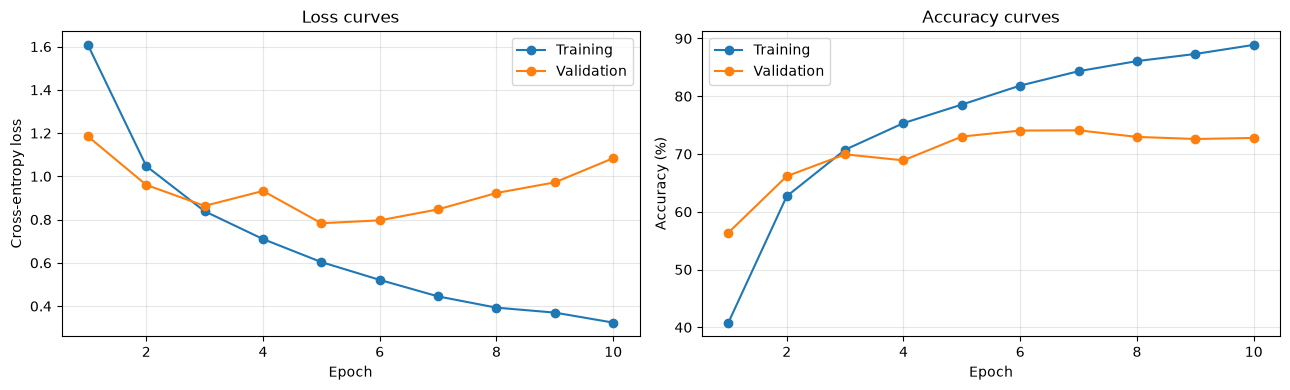

Final training accuracy  : 88.89%
Final validation accuracy: 72.78%
Final accuracy gap       : 16.11 percentage points
Minimum validation loss  : 0.7832 at epoch 5; final validation loss: 1.0839


In [ ]:
epoch_numbers = range(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epoch_numbers, history['train_loss'], marker='o', label='Training')
axes[0].plot(epoch_numbers, history['val_loss'], marker='o', label='Validation')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].set_title('Loss curves')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    epoch_numbers,
    [accuracy * 100 for accuracy in history['train_acc']],
    marker='o',
    label='Training',
)
axes[1].plot(
    epoch_numbers,
    [accuracy * 100 for accuracy in history['val_acc']],
    marker='o',
    label='Validation',
)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Accuracy curves')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

final_train_acc = history['train_acc'][-1] * 100
final_val_acc = history['val_acc'][-1] * 100
generalization_gap = final_train_acc - final_val_acc
min_val_loss = min(history['val_loss'])
min_val_loss_epoch = history['val_loss'].index(min_val_loss) + 1

print(f'Final training accuracy  : {final_train_acc:.2f}%')
print(f'Final validation accuracy: {final_val_acc:.2f}%')
print(f'Final accuracy gap       : {generalization_gap:.2f} percentage points')
print(
    f'Minimum validation loss  : {min_val_loss:.4f} at epoch {min_val_loss_epoch}; '
    f'final validation loss: {history["val_loss"][-1]:.4f}'
)

## 3. Misclassifications and confusing classes

The best checkpoint is evaluated on all 5,000 validation images. The confusion matrix rows are true classes and columns are predicted classes. Per-class accuracy is recall: the fraction of each true class classified correctly.

In [7]:
model.eval()
all_targets = []
all_predictions = []
wrong_images = []
wrong_targets = []
wrong_predictions = []
wrong_confidence = []

with torch.no_grad():
    for images, targets in val_loader:
        probabilities = torch.softmax(model(images.to(device)), dim=1)
        confidence, predictions = probabilities.max(dim=1)
        predictions = predictions.cpu()
        confidence = confidence.cpu()
        wrong = predictions != targets

        all_targets.append(targets)
        all_predictions.append(predictions)
        wrong_images.append(images[wrong])
        wrong_targets.append(targets[wrong])
        wrong_predictions.append(predictions[wrong])
        wrong_confidence.append(confidence[wrong])

all_targets = torch.cat(all_targets)
all_predictions = torch.cat(all_predictions)
wrong_images = torch.cat(wrong_images)
wrong_targets = torch.cat(wrong_targets)
wrong_predictions = torch.cat(wrong_predictions)
wrong_confidence = torch.cat(wrong_confidence)

confusion = torch.bincount(
    all_targets * len(class_names) + all_predictions,
    minlength=len(class_names) ** 2,
).reshape(len(class_names), len(class_names))
class_accuracy = confusion.diag().float() / confusion.sum(dim=1)

error_rate = len(wrong_targets) / len(val_ds) * 100
print(f'Misclassified images: {len(wrong_targets)} / {len(val_ds)} ({error_rate:.2f}%)')
print('\nPer-class validation accuracy:')
for index, name in enumerate(class_names):
    correct = int(confusion[index, index])
    total = int(confusion[index].sum())
    print(f'{name:12s} {class_accuracy[index] * 100:6.2f}%  ({correct}/{total})')

print('\nLowest-accuracy classes:')
for index in torch.argsort(class_accuracy)[:3]:
    print(f'{class_names[index]}: {class_accuracy[index] * 100:.2f}%')

pairs = []
for first in range(len(class_names)):
    for second in range(first + 1, len(class_names)):
        total = int(confusion[first, second] + confusion[second, first])
        pairs.append((total, first, second))

print('\nMost confusing class pairs:')
for total, first, second in sorted(pairs, reverse=True)[:5]:
    first_to_second = int(confusion[first, second])
    second_to_first = int(confusion[second, first])
    print(
        f'{class_names[first]} ↔ {class_names[second]}: {total} errors '
        f'({class_names[first]} → {class_names[second]}: {first_to_second}; '
        f'{class_names[second]} → {class_names[first]}: {second_to_first})'
    )

Misclassified images: 1295 / 5000 (25.90%)

Per-class validation accuracy:
airplane      73.77%  (360/488)
automobile    90.04%  (461/512)
bird          66.17%  (352/532)
cat           65.18%  (307/471)
deer          66.03%  (311/471)
dog           58.37%  (300/514)
frog          75.35%  (382/507)
horse         78.00%  (390/500)
ship          87.50%  (441/504)
truck         80.04%  (401/501)

Lowest-accuracy classes:
dog: 58.37%
cat: 65.18%
deer: 66.03%

Most confusing class pairs:
cat ↔ dog: 188 errors (cat → dog: 65; dog → cat: 123)
automobile ↔ truck: 79 errors (automobile → truck: 26; truck → automobile: 53)
cat ↔ frog: 78 errors (cat → frog: 18; frog → cat: 60)
bird ↔ cat: 76 errors (bird → cat: 53; cat → bird: 23)
bird ↔ deer: 71 errors (bird → deer: 42; deer → bird: 29)


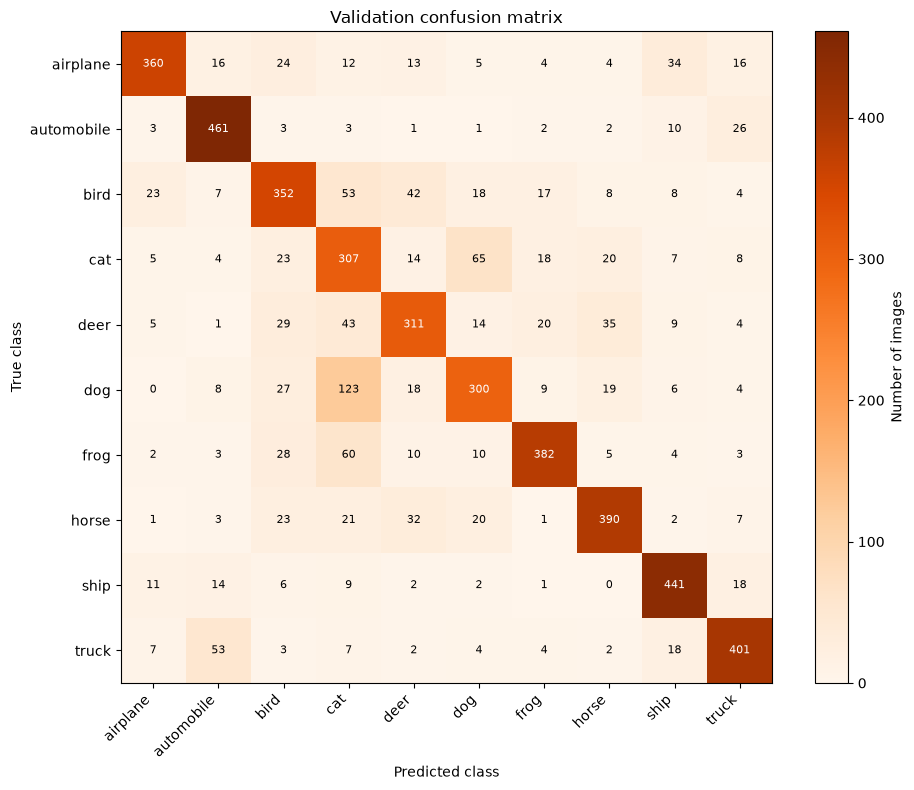

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
confusion_values = confusion.numpy()
image = ax.imshow(confusion_values, cmap='Oranges')
ax.set_xticks(range(len(class_names)), labels=class_names, rotation=45, ha='right')
ax.set_yticks(range(len(class_names)), labels=class_names)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
ax.set_title('Validation confusion matrix')
fig.colorbar(image, ax=ax, label='Number of images')

for row in range(len(class_names)):
    for column in range(len(class_names)):
        value = confusion_values[row, column]
        color = 'white' if value > confusion_values.max() / 2 else 'black'
        ax.text(column, row, str(value), ha='center', va='center', color=color, fontsize=8)

plt.tight_layout()
plt.show()

### Highest-confidence mistakes

These are errors for which the model assigned the largest softmax probability to an incorrect prediction. They are useful for finding overconfident predictions and visually similar classes.

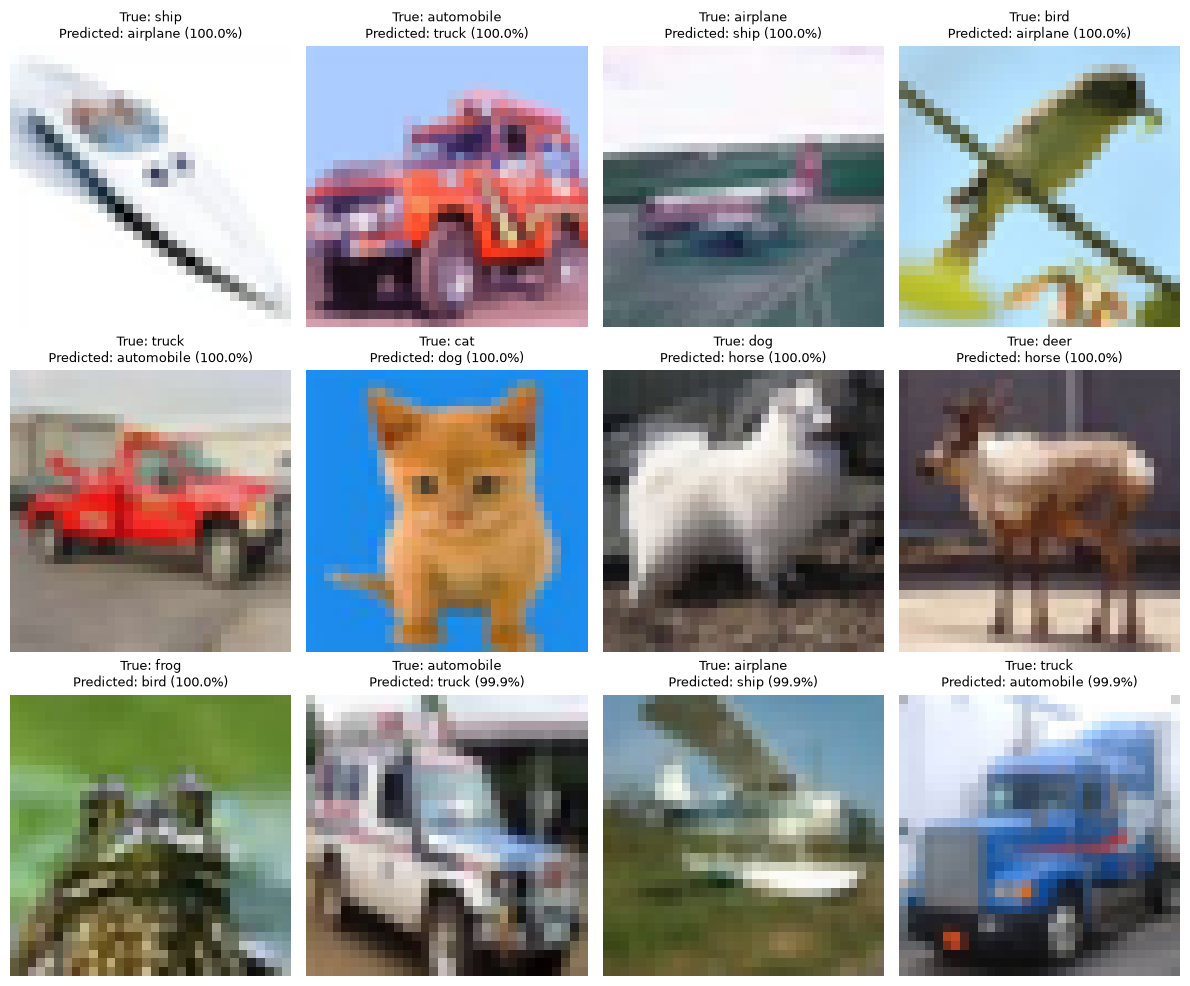

In [9]:
top_wrong = torch.argsort(wrong_confidence, descending=True)[:12]
fig, axes = plt.subplots(3, 4, figsize=(12, 10))

for ax, index in zip(axes.flat, top_wrong):
    image = wrong_images[index].permute(1, 2, 0).numpy()
    image = np.clip(image * 0.5 + 0.5, 0, 1)
    true_name = class_names[wrong_targets[index]]
    predicted_name = class_names[wrong_predictions[index]]
    confidence = wrong_confidence[index].item()
    ax.imshow(image)
    ax.set_title(
        f'True: {true_name}\nPredicted: {predicted_name} ({confidence:.1%})',
        fontsize=9,
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

## 4. Findings and next improvements

### Findings

- **Misclassifications:** The best checkpoint came from epoch 7 with **74.10% validation accuracy**. It misclassified **1,295 of 5,000 validation images (25.90%)**.
- **Confusing classes:** The largest pair was **cat ↔ dog: 188 errors** (65 cat → dog and 123 dog → cat). Other frequent pairs were automobile ↔ truck (79), cat ↔ frog (78), bird ↔ cat (76), and bird ↔ deer (71).
- **Weak classes:** Dog had the lowest per-class accuracy at **58.37%**, followed by cat at **65.18%** and deer at **66.03%**. In contrast, automobile reached 90.04% and ship reached 87.50%.
- **Image evidence:** The highest-confidence gallery contains visually similar animals and vehicles, with several incorrect predictions close to 100% confidence. This shows that some errors are both visually ambiguous and highly overconfident.
- **Underfitting vs. overfitting:** **Overfitting is the dominant problem.** Training accuracy rose to **88.89%**, while final validation accuracy was **72.78%**, a **16.11-point gap**. Validation loss was lowest at epoch 5 (**0.7832**) and increased to **1.0839** by epoch 10, even though training loss continued falling. The best validation accuracy occurred at epoch 7 and then declined.

### Next improvements

1. **Reduce overfitting with data augmentation.** Start with random cropping with padding and random horizontal flipping. These expose the model to changes in position, pose, and background without changing class semantics. Compare against the same baseline before adding other changes.
2. **Add regularization and improve optimization.** Try weight decay with SGD, then test BatchNorm in the deeper CNN and a learning-rate scheduler. Lab 2 showed small gains from BatchNorm and the largest gain from depth, so their combination is a reasonable controlled follow-up. Keep the best-validation checkpoint or use early stopping.
3. **Address overconfident errors.** Try label smoothing and repeat the high-confidence error analysis. It may improve confidence calibration, but its effect on validation accuracy should still be measured.
4. **Track class-level effects.** After each change, compare cat/dog recall and the automobile/truck confusion rather than relying only on overall accuracy. Class weighting is not the first choice because the validation classes are approximately balanced; better features and augmentation target the observed confusions more directly.

**Next experiment:** Retrain the deeper CNN with random crop and horizontal flip, keep all other settings fixed, and repeat this error analysis. Evaluate the official test set only after choosing a final configuration using validation results.